rcp8.5 gwl_2
rcp8.5 gwl_1_5
rcp8.5 gwl_4
rcp2.6 gwl_1_5
rcp2.6 gwl_2
rcp2.6 gwl_4


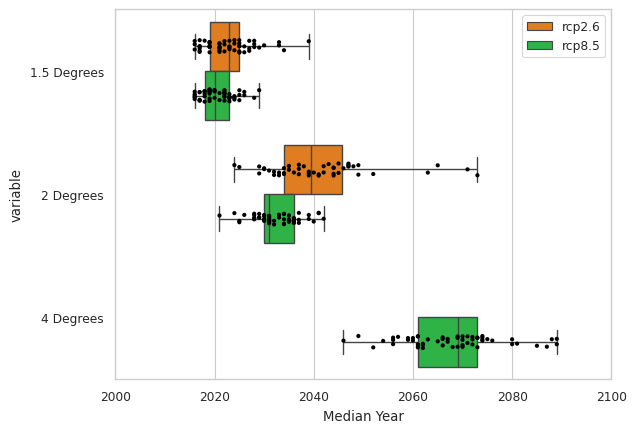

In [1]:
from ffdi_variables_analysis import get_ens_df, plot_gwl_year
import pandas as pd
import cftime
import iris

# Load the ensemble jobids and GWLs
ensdf = get_ens_df()
df = ensdf.copy()
plot_gwl_year(ensdf)

In [3]:
df

,rcp,hist,fut,gwl_1_5_start,gwl_2_start,gwl_4_start
0,rcp2.6,akowa,akuka,2007.0,2019.0,<NA>
1,rcp2.6,akowb,akukb,2011.0,2037.0,<NA>
2,rcp2.6,akowc,akukc,2023.0,2037.0,<NA>
3,rcp2.6,akowe,akuke,2009.0,2023.0,<NA>
4,rcp2.6,akowf,akukf,2013.0,2035.0,<NA>
...,...,...,...,...,...,...
109,rcp8.5,akozl,aldsl,2013.0,2027.0,2062.0
110,rcp8.5,akozn,aldsn,2006.0,2021.0,2064.0
111,rcp8.5,akozo,aldso,2006.0,2020.0,2051.0
112,rcp8.5,akozp,aldsp,2006.0,2023.0,2062.0


In [4]:
country_list = ['Australia', 'Brazil', 'United States of America']
# country_list = ['Australia', 'Brazil', 'South Africa', 'United States of America']
clen = len(country_list)

In [6]:
df_final1 = pd.read_csv(f'/data/users/andrew.hartley/Projects/FFDI_Paper/data/odf_bigdata_{clen}countries_12_to_24.csv')
df_final2 = pd.read_csv(f'/data/users/andrew.hartley/Projects/FFDI_Paper/data/odf_bigdata_{clen}countries_gt_24.csv')


In [7]:
df_final = pd.concat([df_final1, df_final2], ignore_index=True)

In [8]:
df_final.columns

Index(['0', 't', 'x', 'y', 'gwl', 'ensemble_member', 'rcp', 'FFDI',
       'air_temperature', 'precipitation_in_mpersec', 'relative_humidity',
       'soil_moisture_content_top_metre', 'windspeed_in_km_per_hr', 'names'],
      dtype='object')

In [9]:
df_final['ffdi_class'] = 0

class12_24 = (df_final.FFDI >= 12) & (df_final.FFDI < 24) 
df_final['ffdi_class'].loc[class12_24] = '12 <= FFDI < 24'

class_gt24 = (df_final.FFDI >= 24)
df_final['ffdi_class'].loc[class_gt24] = 'FFDI >= 24'

## Create some initial scatter plots

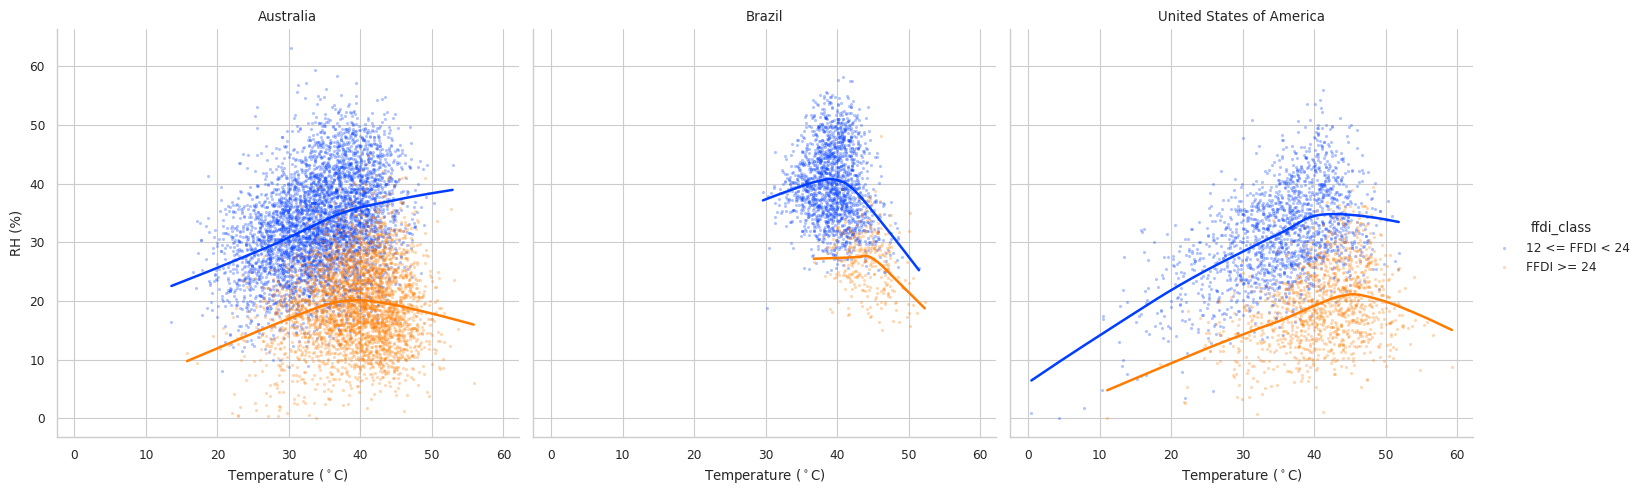

In [11]:
# vars = ['relative_humidity', 'soil_moisture_content_top_metre', 'precipitation_in_mpersec', 'windspeed_in_km_per_hr', 'air_temperature']
import seaborn as sns
import matplotlib.pyplot as plt

gwl_order = ['Baseline', 'GWL1.5', 'GWL2', 'GWL4']
country_order = country_list

# g = sns.lmplot(data=df_final_long.loc[(df_final_long.gwl == 'Baseline') | (df_final_long.gwl == 'GWL4')].sample(frac=0.05, replace=False), x='FFDI', y='value', hue='gwl', row='variable', row_order=var_order, col='names', col_order=country_order, hue_order=gwl_order, palette="bright", aspect=2.7, height=1.7, lowess=True, facet_kws={'sharex': True, 'sharey': False}, scatter_kws={'alpha':0.3, 'linewidths': 0, 's': 5})  # size='soil_moisture_content_top_metre', sizes=(1,100), style='rcp', hue='ffdi_class', hue='variable', 

# g.set_titles(row_template='{row_name}', col_template='{col_name}')  
# for i, ax in enumerate(g.axes[:, 0]):
#     ax.set_ylabel(var_units[i])


g = sns.lmplot(data=df_final.sample(frac=0.1, replace=False), 
               x='air_temperature', y='relative_humidity', hue='ffdi_class', col='names', 
               col_order=country_order, col_wrap=clen, palette="bright", lowess=True, 
               facet_kws={'sharex': True, 'sharey': True}, scatter_kws={'alpha':0.3, 'linewidths': 0, 's': 5})  # style='rcp', size='FFDI', sizes=(1,100), hue_order=gwl_order, 
[plt.setp(ax.texts, text="") for ax in g.axes.flat]
g.set_titles(col_template='{col_name}')
g.set_axis_labels(x_var="Temperature ($^\circ$C)", y_var="RH (%)")

plt.savefig(f'/data/users/andrew.hartley/Projects/FFDI_Paper/plots/meteorological-drivers-{clen}countries_ffdi-class.png')

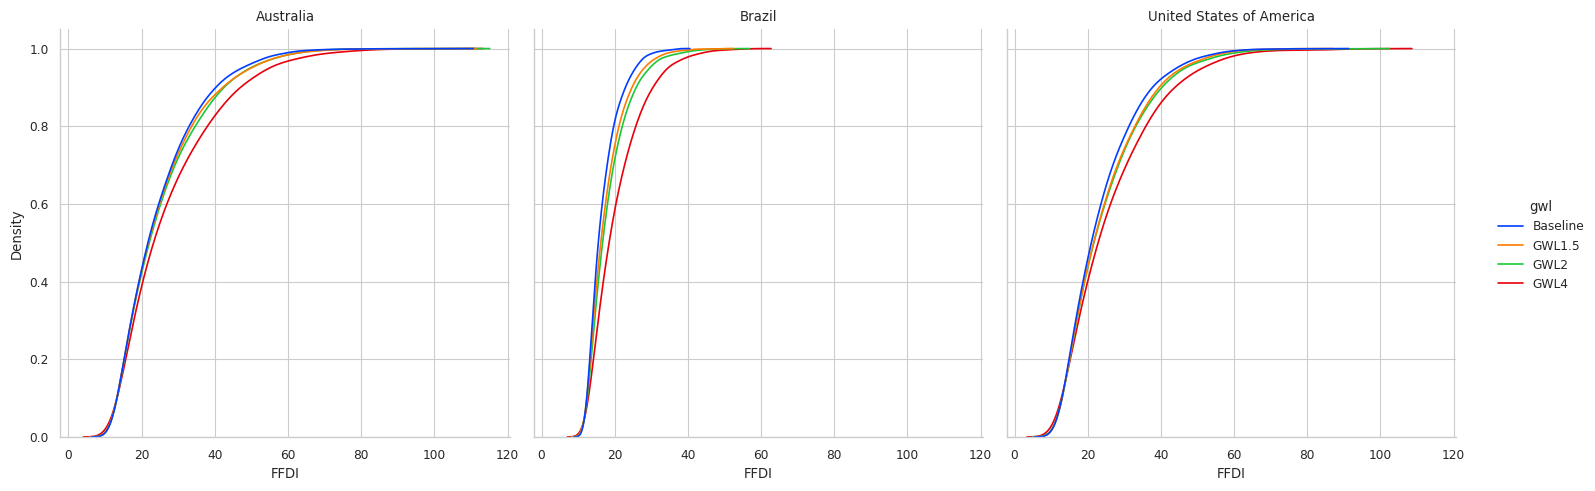

In [13]:
g = sns.displot(data=df_final.sample(frac=0.3, replace=False), 
                x="FFDI", hue="gwl", col='names', 
                col_order=country_order, hue_order=gwl_order, kind="kde", 
                log_scale=False, cumulative=True, common_norm=False, palette="bright")
g.set_titles(col_template='{col_name}')  
plt.savefig(f'/data/users/andrew.hartley/Projects/FFDI_Paper/plots/meteorological-drivers-{clen}countries_ffdi-CDF.png')

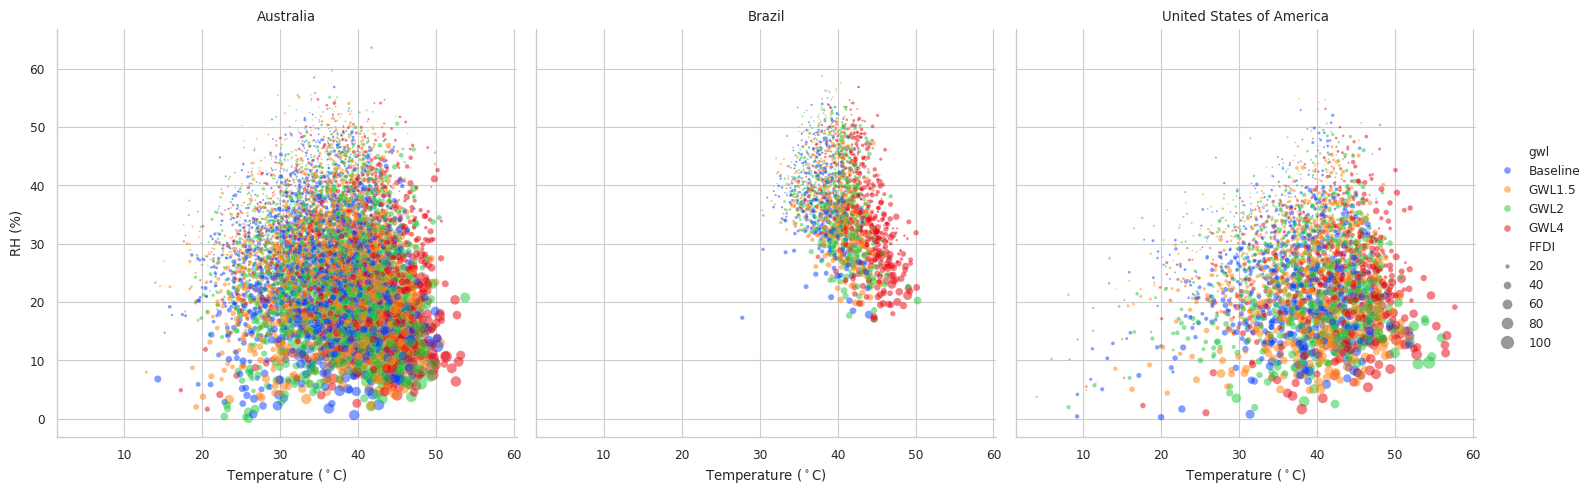

In [14]:
g = sns.relplot(data=df_final.sample(frac=0.1, replace=False), 
                x='air_temperature', y='relative_humidity', hue='gwl', size='FFDI', 
                sizes=(1,100), alpha=.5, kind='scatter', hue_order=gwl_order, 
                col='names', col_order=country_order, col_wrap=clen, palette="bright")  # style='rcp', 
[plt.setp(ax.texts, text="") for ax in g.axes.flat]
g.set_titles(col_template='{col_name}')
g.set_axis_labels(x_var="Temperature ($^\circ$C)", y_var="RH (%)")
plt.savefig(f'/data/users/andrew.hartley/Projects/FFDI_Paper/plots/meteorological-drivers-{clen}countries_temp-vs-rh.png')

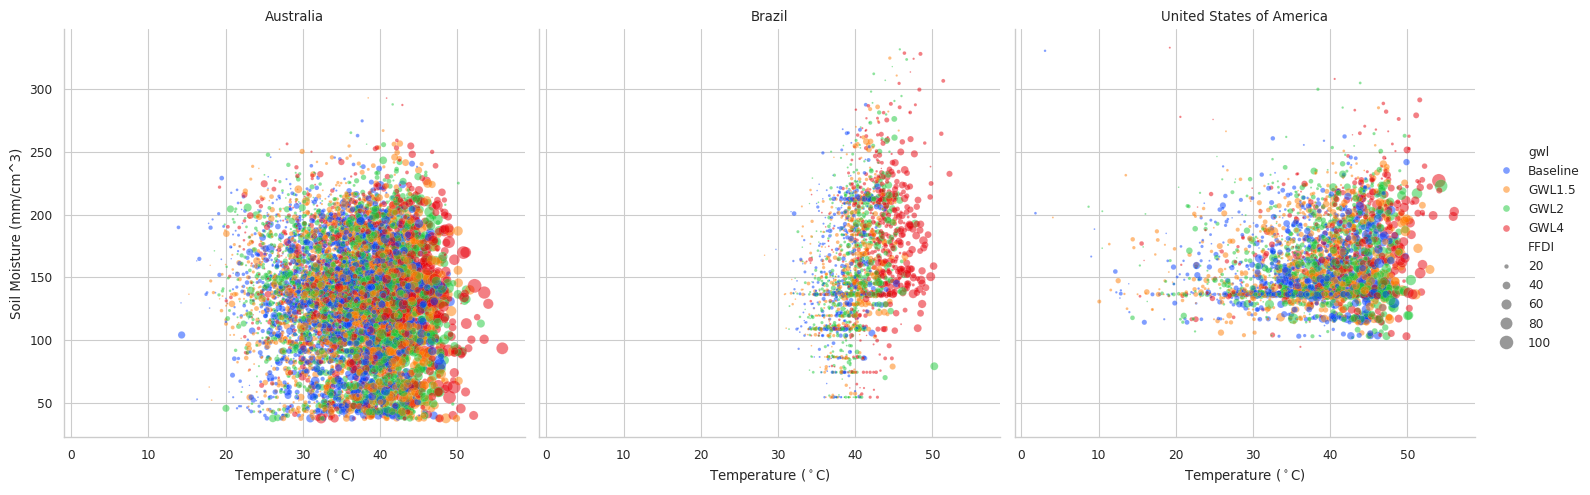

In [15]:
g = sns.relplot(data=df_final.sample(frac=0.1, replace=False), 
                x='air_temperature', y='soil_moisture_content_top_metre', hue='gwl', size='FFDI', 
                sizes=(1,100), alpha=.5, kind='scatter', hue_order=gwl_order, 
                col='names', col_order=country_order, col_wrap=clen, palette="bright")  # style='rcp', 
[plt.setp(ax.texts, text="") for ax in g.axes.flat]
g.set_titles(col_template='{col_name}')
g.set_axis_labels(x_var="Temperature ($^\circ$C)", y_var="Soil Moisture (mm/cm^3)")

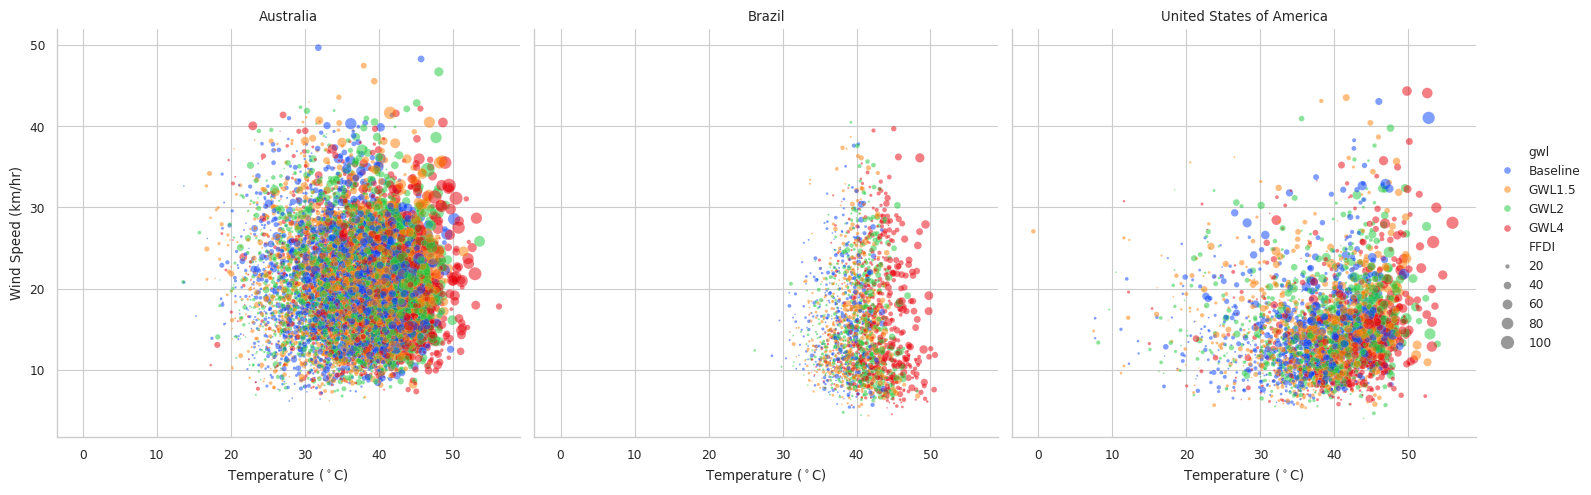

In [16]:
g = sns.relplot(data=df_final.sample(frac=0.1, replace=False), 
                x='air_temperature', y='windspeed_in_km_per_hr', hue='gwl', size='FFDI', 
                sizes=(1,100), alpha=.5, kind='scatter', hue_order=gwl_order, 
                col='names', col_wrap=clen, col_order=country_order, palette="bright")  # style='rcp', 
[plt.setp(ax.texts, text="") for ax in g.axes.flat]
g.set_titles(col_template='{col_name}')
g.set_axis_labels(x_var="Temperature ($^\circ$C)", y_var="Wind Speed (km/hr)") 

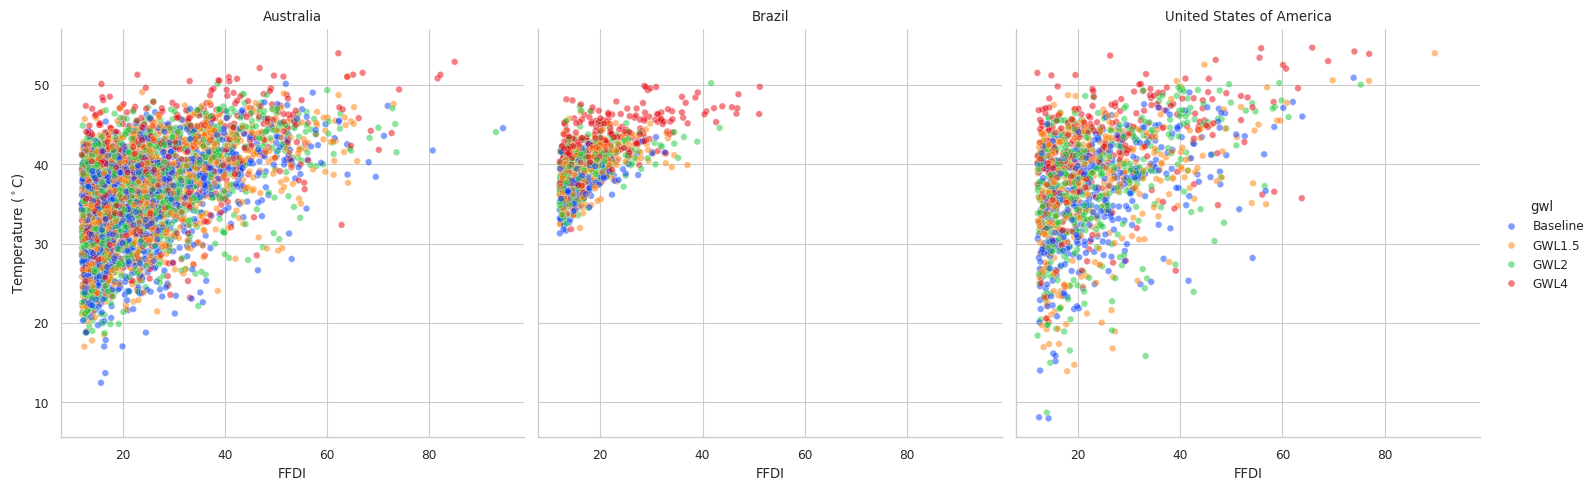

In [17]:
g = sns.relplot(data=df_final.sample(frac=0.05, replace=False), 
                x='FFDI', y='air_temperature', hue='gwl', alpha=.5, kind='scatter', 
                hue_order=gwl_order, col='names', col_wrap=clen, col_order=country_order, palette="bright")  # size='soil_moisture_content_top_metre', sizes=(1,100), style='rcp', 
[plt.setp(ax.texts, text="") for ax in g.axes.flat]
g.set_titles(col_template='{col_name}')
g.set_axis_labels(x_var="FFDI", y_var="Temperature ($^\circ$C)")

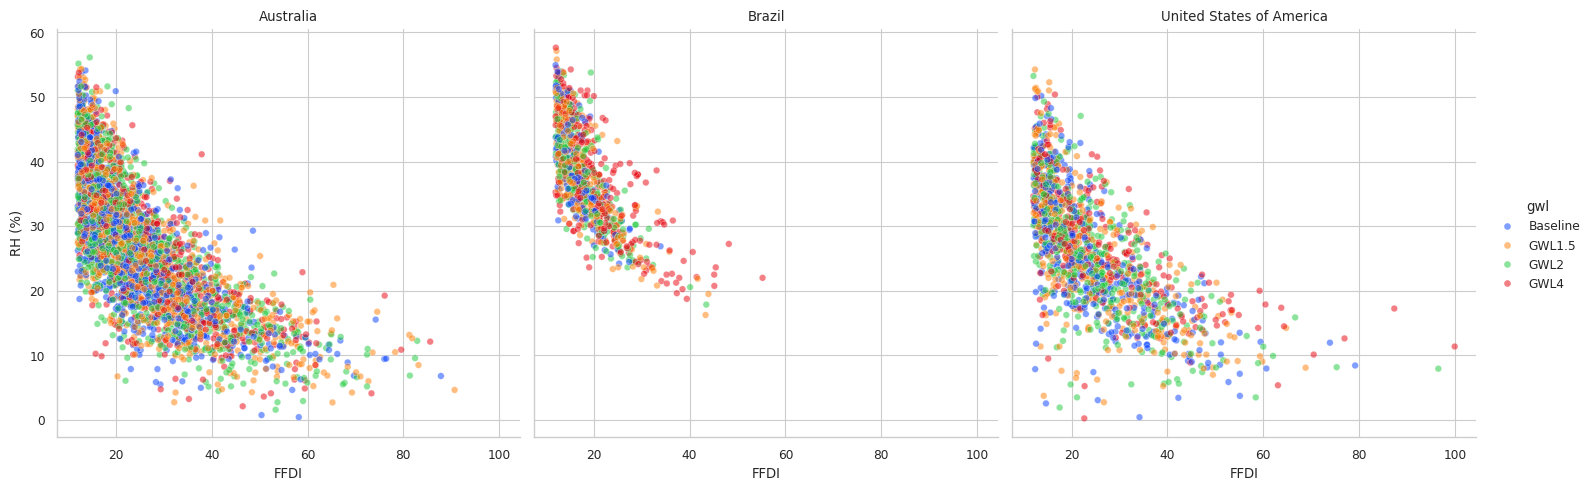

In [18]:
g = sns.relplot(data=df_final.sample(frac=0.05, replace=False), 
                x='FFDI', y='relative_humidity', hue='gwl', alpha=.5, kind='scatter', 
                hue_order=gwl_order, col='names', col_wrap=clen, col_order=country_order, palette="bright")  # size='soil_moisture_content_top_metre', sizes=(1,100), style='rcp', 
[plt.setp(ax.texts, text="") for ax in g.axes.flat]
g.set_titles(col_template='{col_name}')
g.set_axis_labels(x_var="FFDI", y_var="RH (%)")

In [19]:
df_final_long = pd.melt(df_final.groupby(['ffdi_class', 'gwl', 'names'], group_keys=False).apply(lambda x: x.sample(frac=0.1)), 
                        id_vars=['t', 'x', 'y', 'gwl', 'ensemble_member', 'rcp', 'names', 'FFDI', 'ffdi_class'], 
                        value_vars=['air_temperature', 'precipitation_in_mpersec', 'relative_humidity', 'soil_moisture_content_top_metre', 'windspeed_in_km_per_hr'])

In [21]:
df_final_long.loc[df_final_long.variable == 'air_temperature', 'variable'] = '2m Air Temperature'
df_final_long.loc[df_final_long.variable == 'precipitation_in_mpersec', 'variable'] = 'Precipitation'
df_final_long.loc[df_final_long.variable == 'relative_humidity', 'variable'] = 'Relative Humidity'
df_final_long.loc[df_final_long.variable == 'soil_moisture_content_top_metre', 'variable'] = 'Soil Moisture'
df_final_long.loc[df_final_long.variable == 'windspeed_in_km_per_hr', 'variable'] = 'Wind Speed'

In [22]:
pd.unique(df_final_long.variable)

array(['2m Air Temperature', 'Precipitation', 'Relative Humidity',
       'Soil Moisture', 'Wind Speed'], dtype=object)

In [62]:
print(df_final)

               0                    t       x     y       gwl ensemble_member  \
0        93383.0  1995-12-16 12:00:00  116.25 -32.5  Baseline           akuka   
1       135336.0  1999-11-26 12:00:00  116.25 -32.5  Baseline           akuka   
2       148693.0  2001-08-16 12:00:00  138.75 -20.0  Baseline           akuka   
3       130727.0  1999-08-27 12:00:00  120.00 -22.5  Baseline           akuka   
4       192835.0  2005-10-03 12:00:00  142.50 -25.0  Baseline           akuka   
...          ...                  ...     ...   ...       ...             ...   
128238       NaN  2069-09-02 12:00:00 -101.25  37.5      GWL4           aldsq   
128239       NaN  2067-06-21 12:00:00 -105.00  32.5      GWL4           aldsq   
128240       NaN  2064-06-27 12:00:00  -93.75  32.5      GWL4           aldsq   
128241       NaN  2057-07-06 12:00:00 -108.75  37.5      GWL4           aldsq   
128242       NaN  2062-06-04 12:00:00 -101.25  35.0      GWL4           aldsq   

           rcp       FFDI  

AttributeError: 'Legend' object has no attribute 'legendHandles'

<Figure size 1200x1000 with 0 Axes>

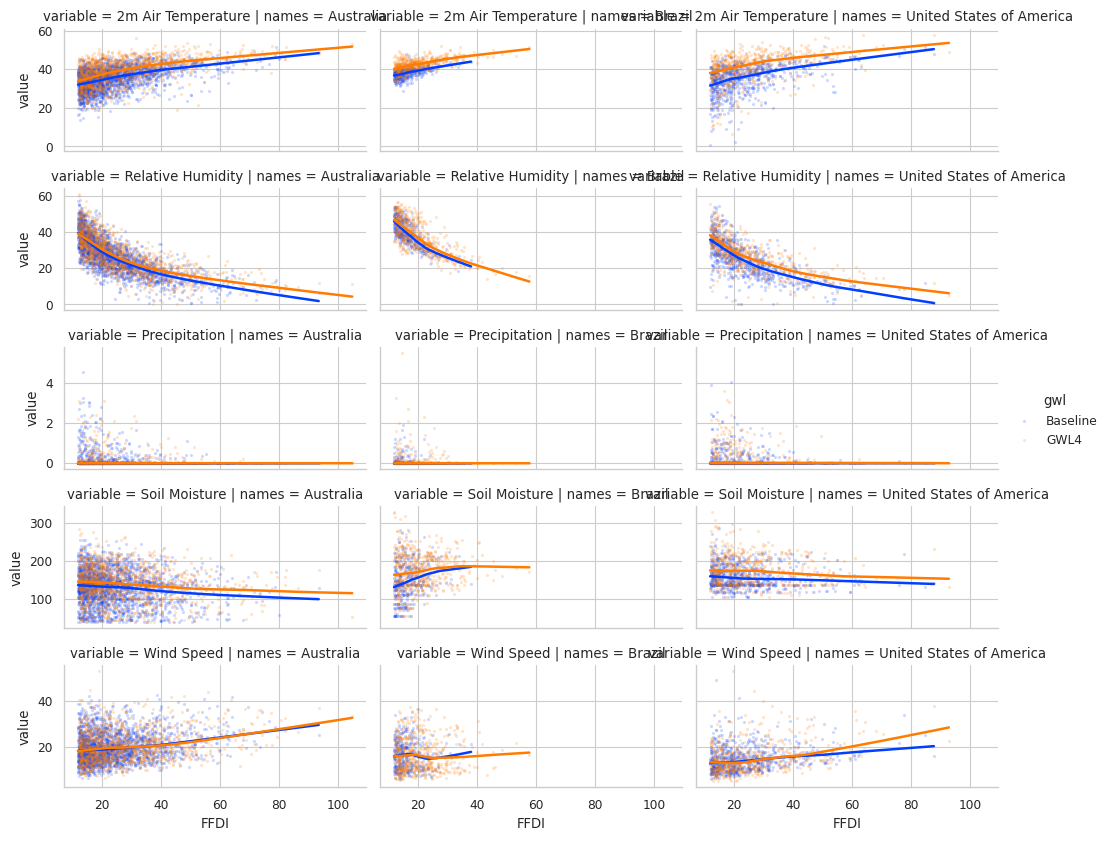

In [47]:
var_order = ['2m Air Temperature', 'Relative Humidity', 'Precipitation', 'Soil Moisture', 'Wind Speed']
var_units = ["Temp ($^\circ$C)", "RH (%)", "Precip (mm/day)", "Soil Moisture (mm/cm^3)", "Wind Speed (km/hr)"]
gwl_order = ['Baseline', 'GWL4']

import matplotlib.pyplot as plt
import seaborn as sns

# Add a border line and white background to the legend
sns.set_style('whitegrid', {"legend.frameon":True})

plt.figure(figsize=(12, 10))

g = sns.lmplot(data=df_final_long.loc[(df_final_long.gwl == 'Baseline') | (df_final_long.gwl == 'GWL4')], 
               x='FFDI', y='value', hue='gwl', row='variable', row_order=var_order, 
               col='names', col_order=country_order, hue_order=gwl_order, 
               palette="bright", aspect=2.0, height=1.7, lowess=True, 
               facet_kws={'sharex': True, 'sharey': 'row'}, scatter_kws={'alpha':0.2, 'linewidths': 0, 's': 5})  # size='soil_moisture_content_top_metre', sizes=(1,100), style='rcp', hue='ffdi_class', hue='variable', 

legend = g._legend
# for lh, lab in g.ax.get_legend_handles_labels():
for lh in legend.legendHandles:
    # Increase the size of points in the legend
    # lh._sizes = [50]  # change 50 to desired size
    # Override the legend opacity
    lh.set_alpha(1)
# plt.legend(markerscale=3, alpha=1)

# Override the legend title and text
legend.set_title("")
for t, l in zip(legend.texts, ["Baseline", "4\u00b0C Global Warming"]):
    t.set_text(l)

# Add a border line and white background to the legend
legend.set_frame_on(True)
legend.get_frame().set_linewidth(1.0)
legend.get_frame().set_edgecolor('black')
legend.get_frame().set_facecolor('white')

# Move the legend to the left
g._legend.set_bbox_to_anchor((0.905, 0.845))  # change -0.1 to desired x position

g.set_titles(row_template='{row_name}', col_template='{col_name}')  
for i, ax in enumerate(g.axes[:, 0]):
    ax.set_ylabel(var_units[i])

plt.savefig(f'/data/users/andrew.hartley/Projects/FFDI_Paper/plots/meteorological-drivers-{clen}countries_baseline-4C.png', bbox_inches='tight')

In [56]:
print(g._legend.markerscale)

1.0


In [24]:
df_final.columns

Index(['0', 't', 'x', 'y', 'gwl', 'ensemble_member', 'rcp', 'FFDI',
       'air_temperature', 'precipitation_in_mpersec', 'relative_humidity',
       'soil_moisture_content_top_metre', 'windspeed_in_km_per_hr', 'names',
       'ffdi_class'],
      dtype='object')

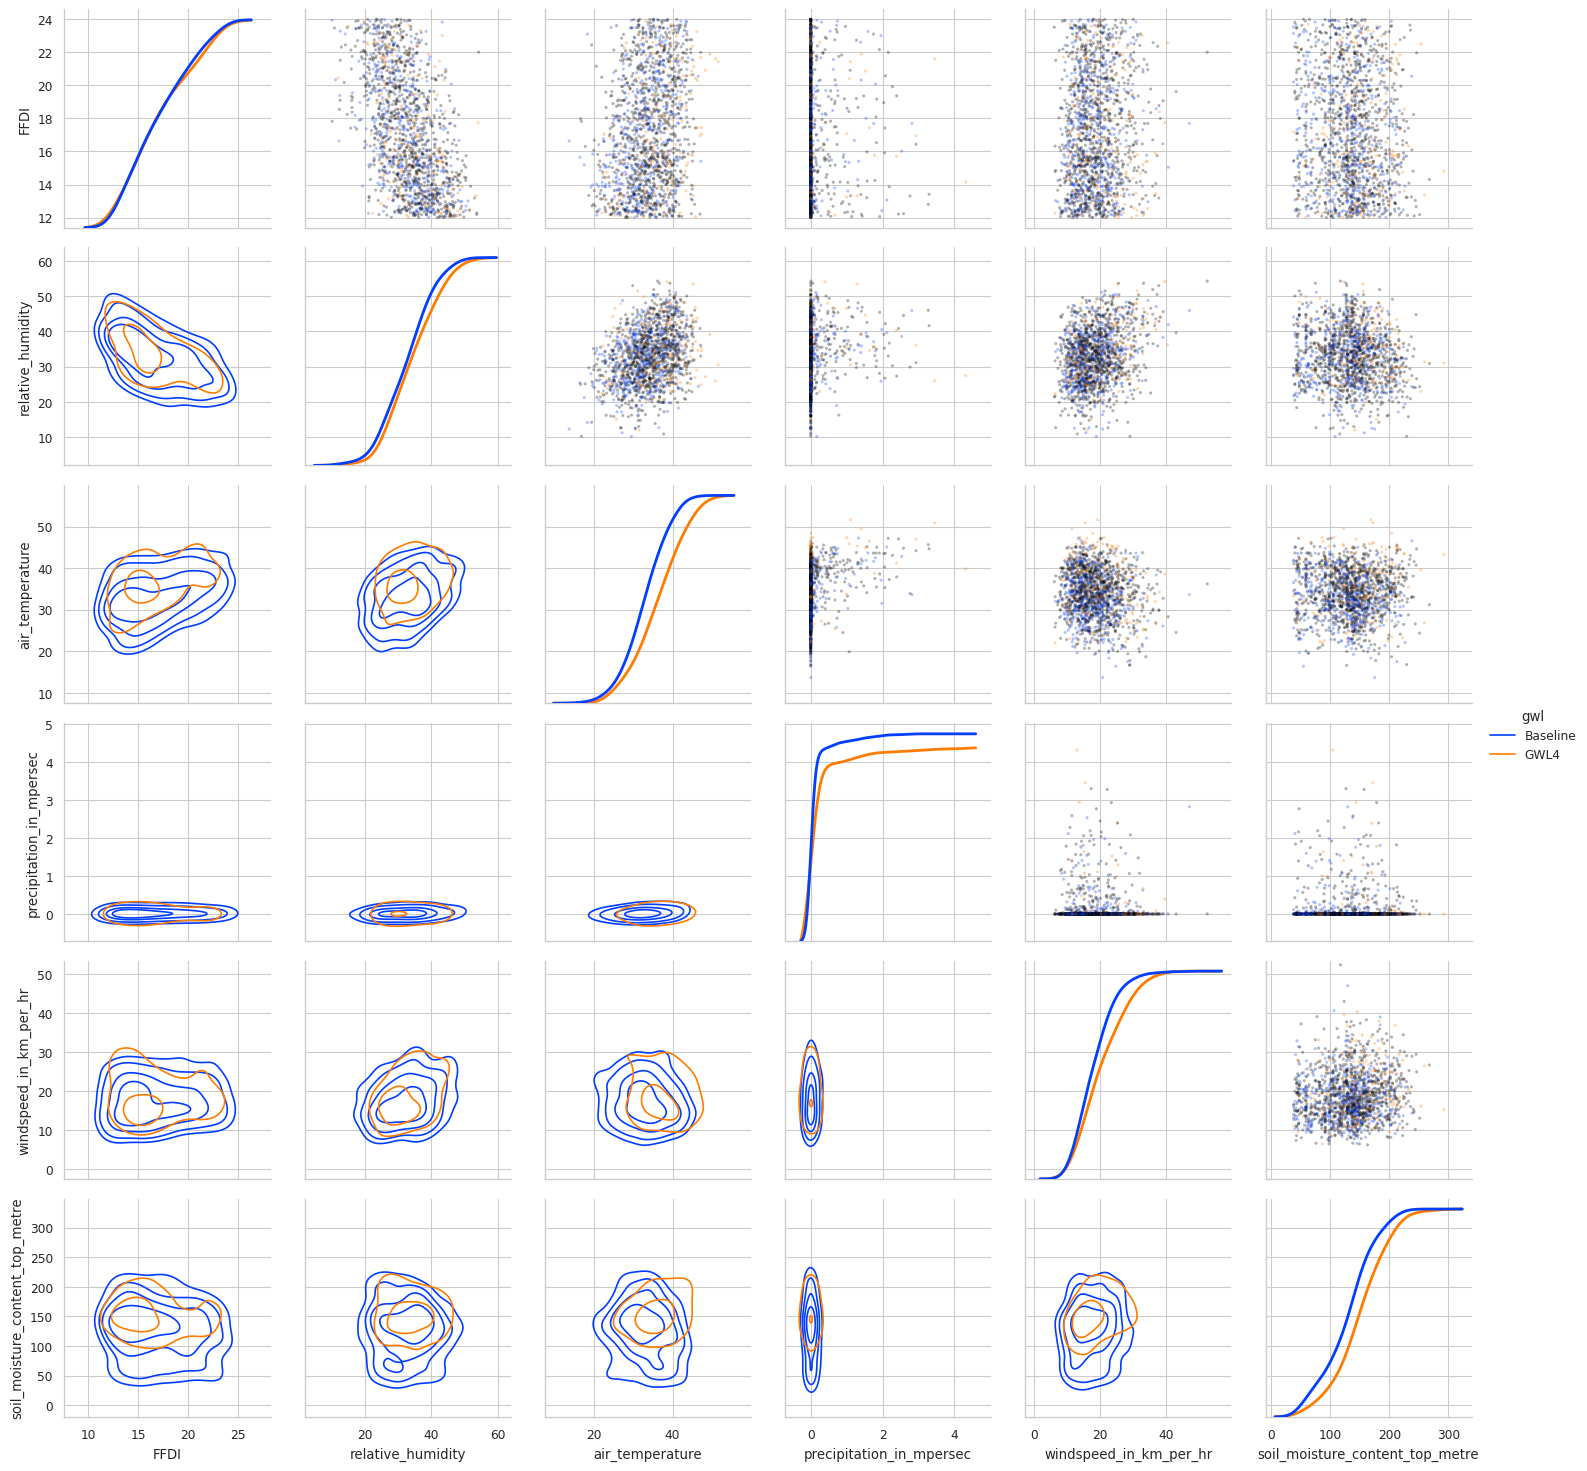

In [25]:
g = sns.PairGrid(data=df_final[df_final.names.isin(['Australia']) & ((df_final_long.gwl == 'Baseline') | (df_final_long.gwl == 'GWL4'))].sample(frac=0.1, replace=False), 
                 vars=['FFDI', 'relative_humidity', 'air_temperature', 'precipitation_in_mpersec', 'windspeed_in_km_per_hr', 'soil_moisture_content_top_metre'], 
                 hue='gwl', palette="bright", hue_order=gwl_order)  # 'Australia', 'United States of America'
g.map_upper(sns.scatterplot, alpha=0.3, linewidths=0, s=5)
g.map_lower(sns.kdeplot, levels=5, thresh=.2)
g.map_diag(sns.kdeplot, lw=2, cumulative=True, common_norm=False, common_grid=True)
# g.map_diag(sns.histplot, multiple='stack')
g.add_legend()
plt.savefig('/data/users/andrew.hartley/Projects/FFDI_Paper/plots/meteorological-drivers-Australia-pairsplot_baseline-vs-4C.png')

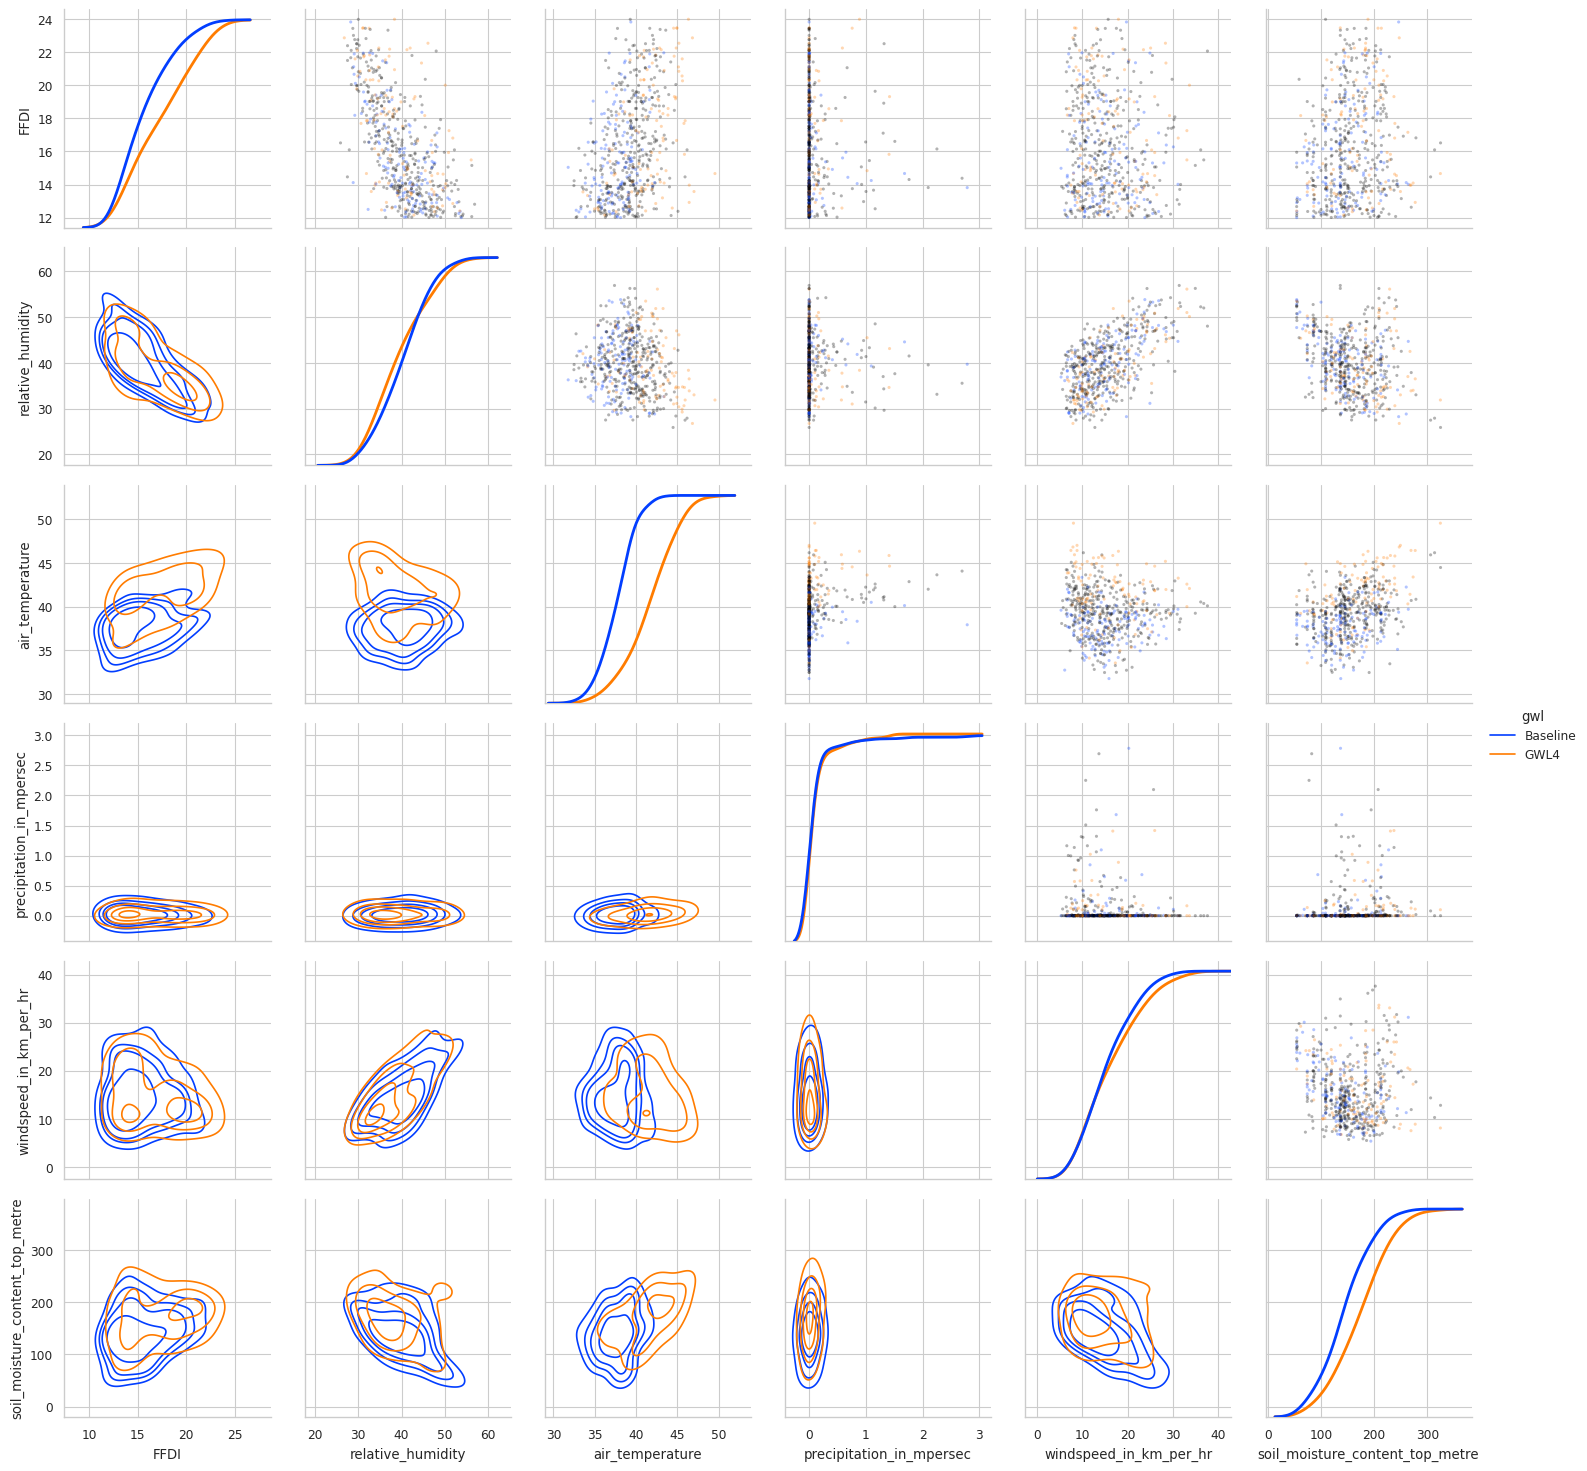

In [26]:
g = sns.PairGrid(data=df_final[df_final.names.isin(['Brazil']) & ((df_final_long.gwl == 'Baseline') | (df_final_long.gwl == 'GWL4'))].sample(frac=0.1, replace=False), 
                 vars=['FFDI', 'relative_humidity', 'air_temperature', 'precipitation_in_mpersec', 'windspeed_in_km_per_hr', 'soil_moisture_content_top_metre'], 
                 hue='gwl', palette="bright", hue_order=gwl_order)  # 'Australia', 'United States of America'
g.map_upper(sns.scatterplot, alpha=0.3, linewidths=0, s=5)
g.map_lower(sns.kdeplot, levels=5, thresh=.2)
g.map_diag(sns.kdeplot, lw=2, cumulative=True, common_norm=False, common_grid=True)
g.add_legend()
plt.savefig('/data/users/andrew.hartley/Projects/FFDI_Paper/plots/meteorological-drivers-Brazil-pairsplot_baseline-vs-4C.png')

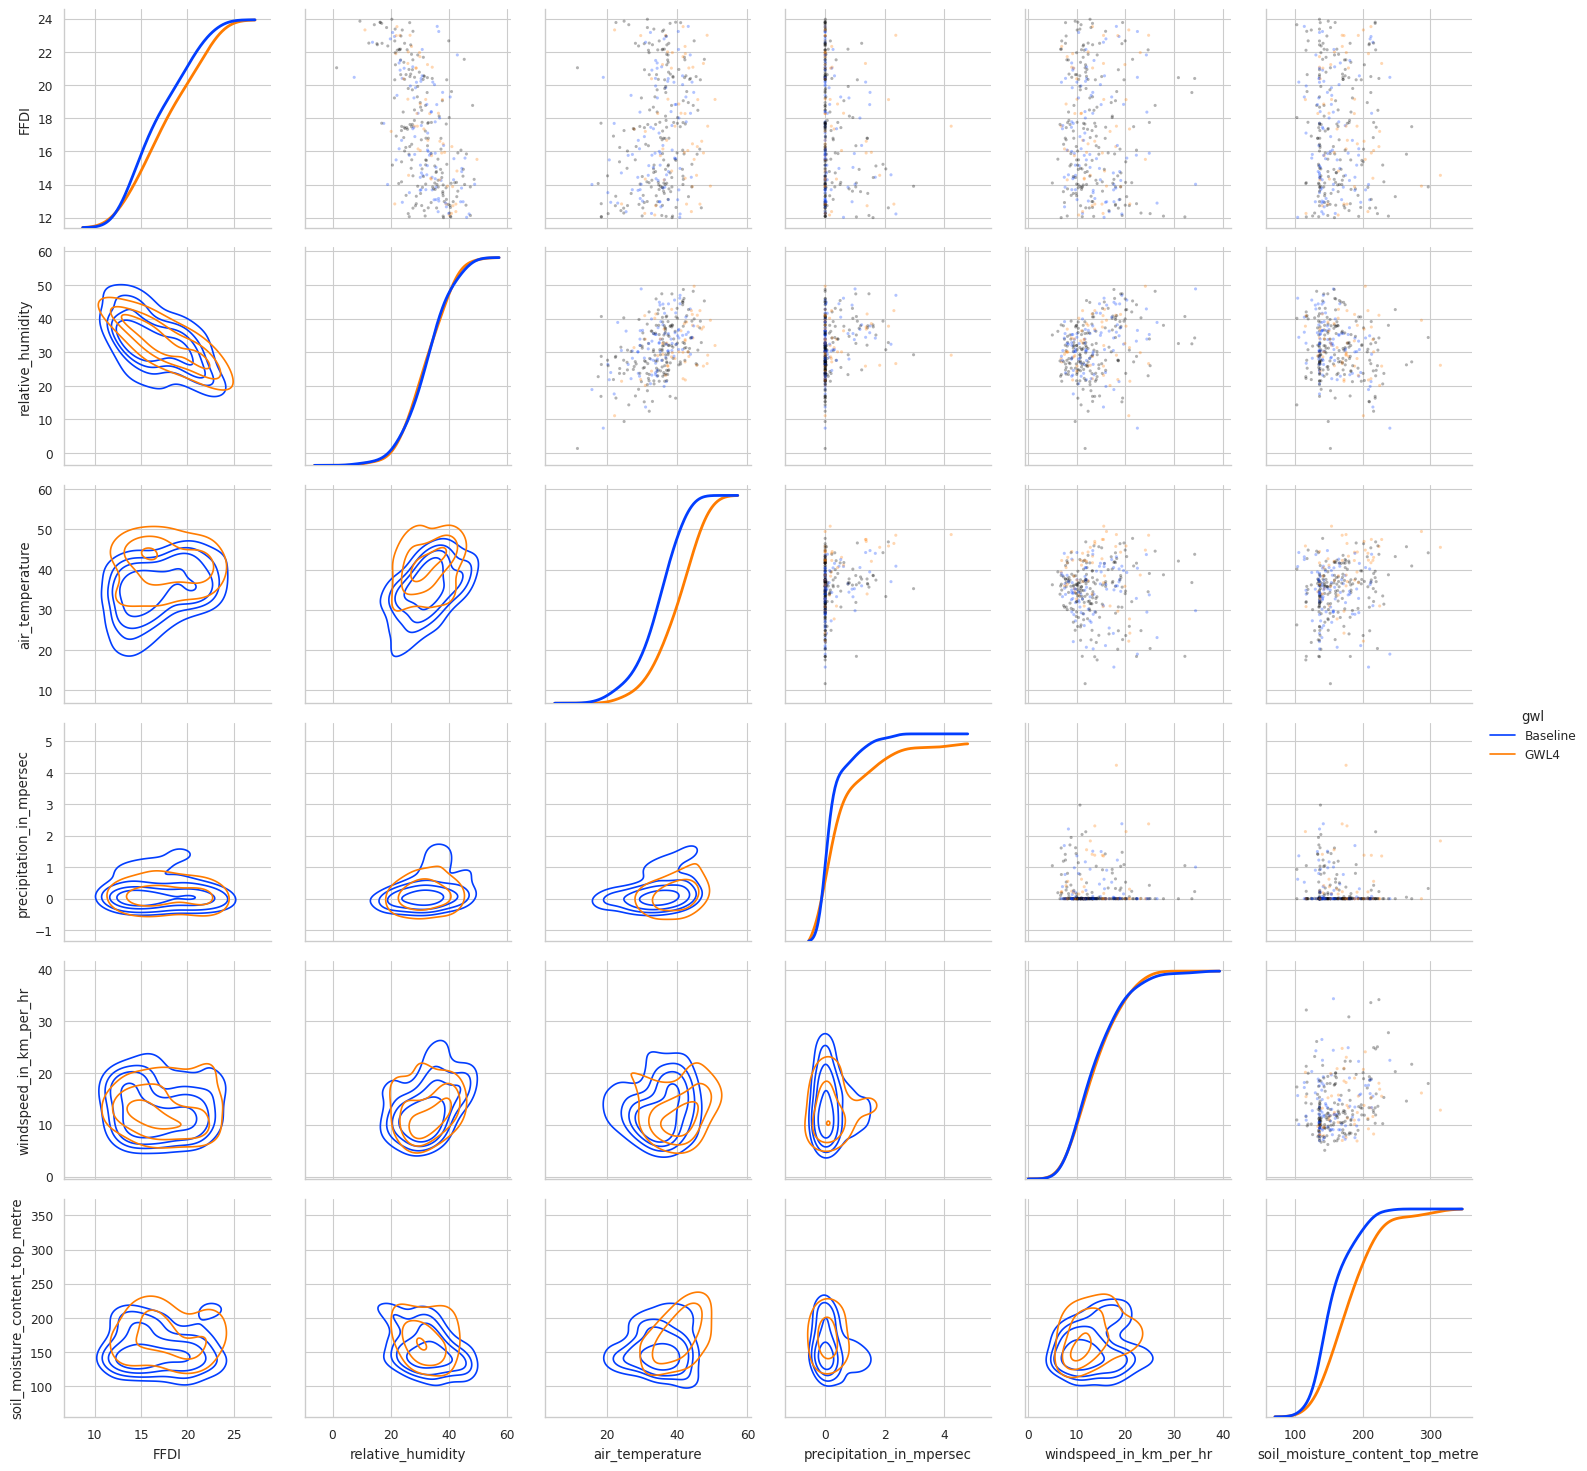

In [27]:
g = sns.PairGrid(data=df_final[df_final.names.isin(['United States of America']) & ((df_final_long.gwl == 'Baseline') | (df_final_long.gwl == 'GWL4'))].sample(frac=0.05, replace=False), 
                 vars=['FFDI', 'relative_humidity', 'air_temperature', 'precipitation_in_mpersec', 'windspeed_in_km_per_hr', 'soil_moisture_content_top_metre'], 
                 hue='gwl', palette="bright", hue_order=gwl_order)  # 'Australia', 'Brazil', 'United States of America'
g.map_upper(sns.scatterplot, alpha=0.3, linewidths=0, s=5)
g.map_lower(sns.kdeplot, levels=5, thresh=.2)
g.map_diag(sns.kdeplot, lw=2, cumulative=True, common_norm=False, common_grid=True)
g.add_legend()
plt.savefig('/data/users/andrew.hartley/Projects/FFDI_Paper/plots/meteorological-drivers-USA-pairsplot_baseline-vs-4C.png')

In [44]:
print(df_final)

               0                    t       x     y       gwl ensemble_member  \
0        93383.0  1995-12-16 12:00:00  116.25 -32.5  Baseline           akuka   
1       135336.0  1999-11-26 12:00:00  116.25 -32.5  Baseline           akuka   
2       148693.0  2001-08-16 12:00:00  138.75 -20.0  Baseline           akuka   
3       130727.0  1999-08-27 12:00:00  120.00 -22.5  Baseline           akuka   
4       192835.0  2005-10-03 12:00:00  142.50 -25.0  Baseline           akuka   
...          ...                  ...     ...   ...       ...             ...   
128238       NaN  2069-09-02 12:00:00 -101.25  37.5      GWL4           aldsq   
128239       NaN  2067-06-21 12:00:00 -105.00  32.5      GWL4           aldsq   
128240       NaN  2064-06-27 12:00:00  -93.75  32.5      GWL4           aldsq   
128241       NaN  2057-07-06 12:00:00 -108.75  37.5      GWL4           aldsq   
128242       NaN  2062-06-04 12:00:00 -101.25  35.0      GWL4           aldsq   

           rcp       FFDI  

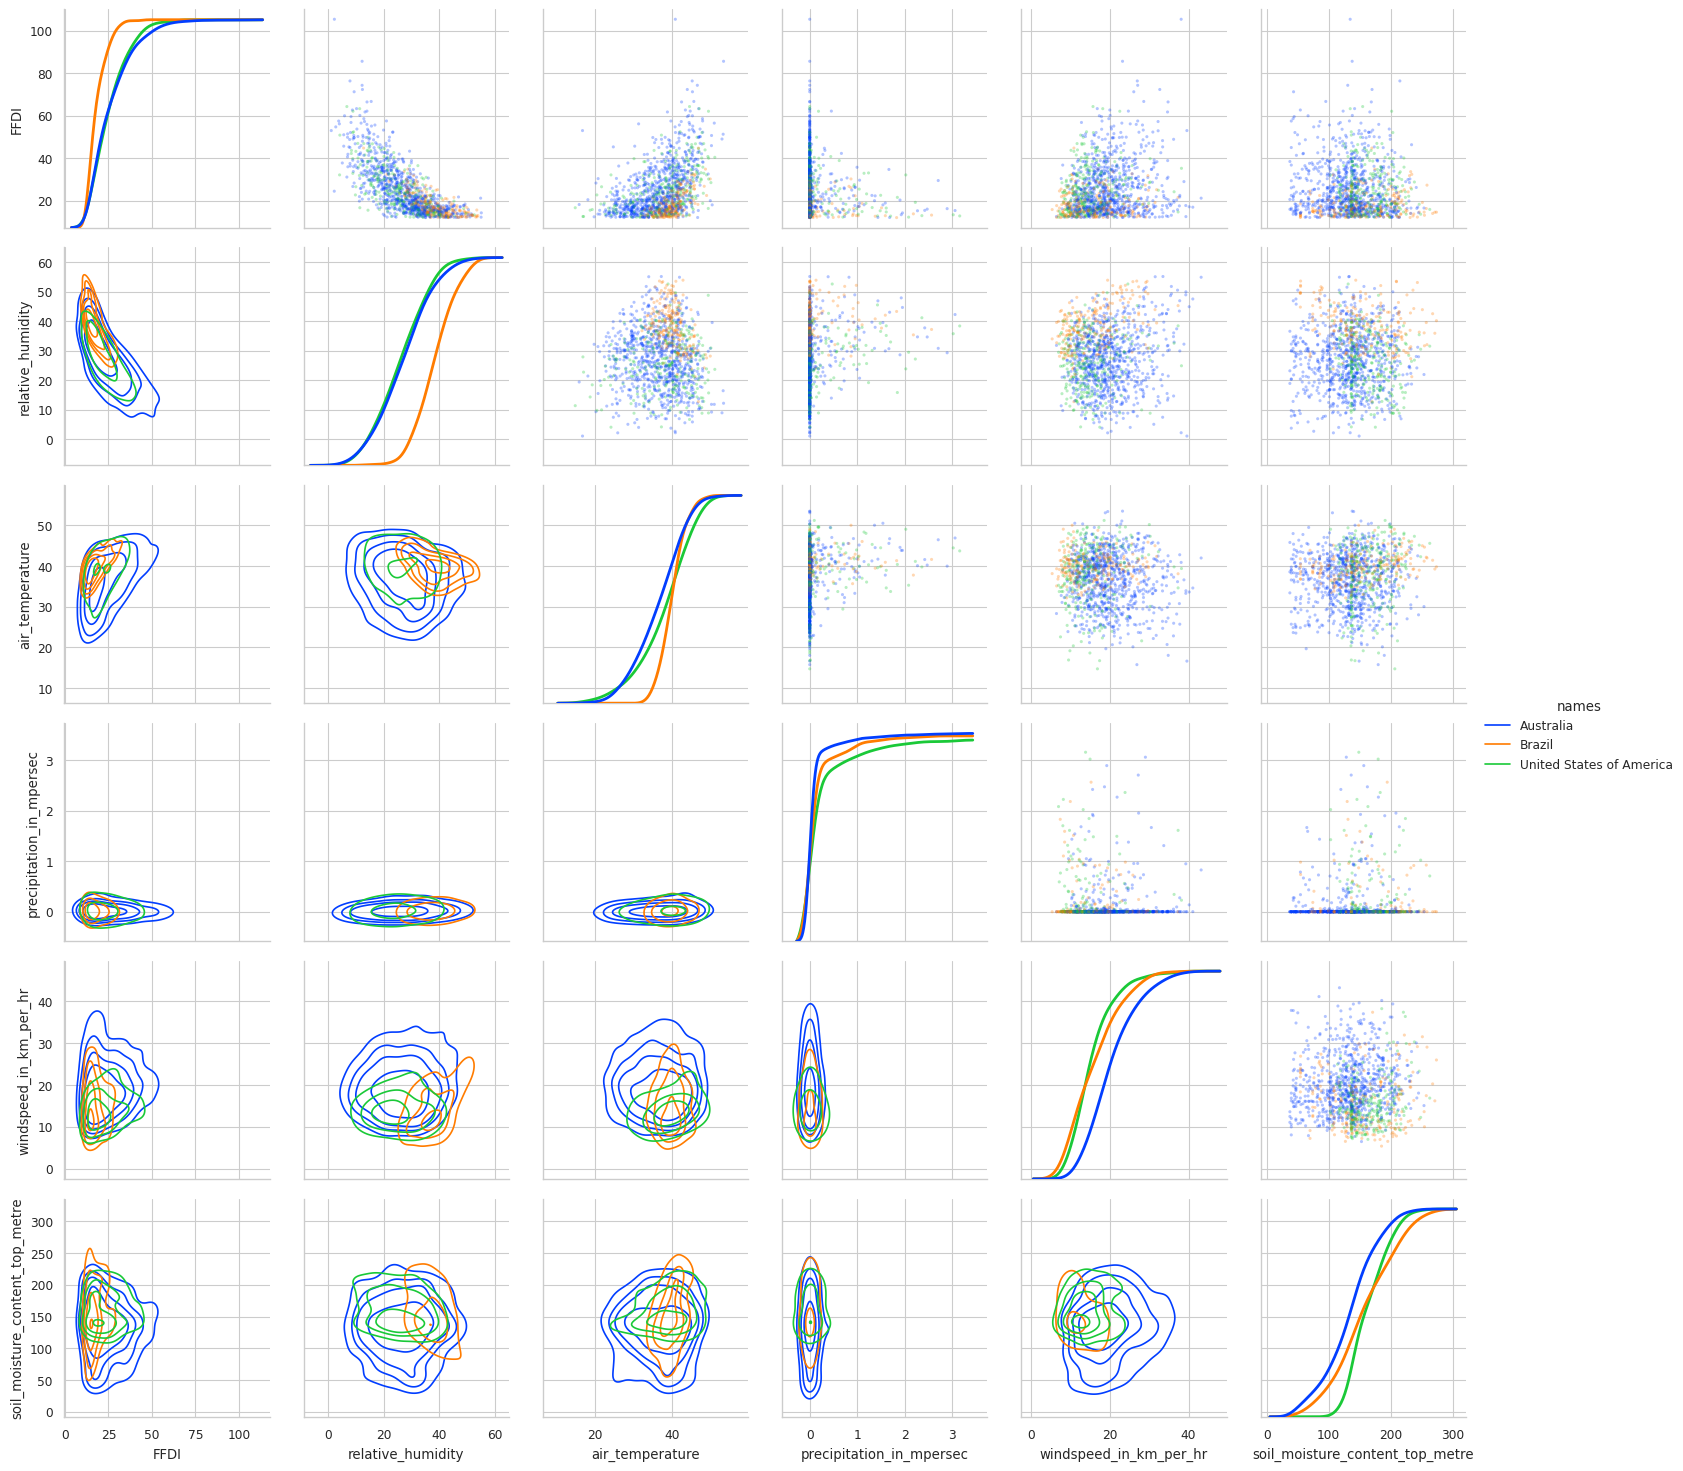

In [28]:
g = sns.PairGrid(data=df_final.sample(frac=0.01, replace=False), 
                 vars=['FFDI', 'relative_humidity', 'air_temperature', 'precipitation_in_mpersec', 'windspeed_in_km_per_hr', 'soil_moisture_content_top_metre'], 
                 hue='names', hue_order=country_order, palette="bright")  # 'Australia', 'Brazil', 'United States of America'
g.map_upper(sns.scatterplot, alpha=0.3, linewidths=0, s=5)
g.map_lower(sns.kdeplot, levels=5, thresh=.2)
g.map_diag(sns.kdeplot, lw=2, cumulative=True, common_norm=False, common_grid=True)
g.add_legend()
plt.savefig(f'/data/users/andrew.hartley/Projects/FFDI_Paper/plots/meteorological-drivers-{clen}countries_pairs-plot.png')

In [29]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
import numpy as np

In [30]:
mysample = df_final[df_final.names.isin(['Australia'])].sample(frac=0.1, replace=False)
mysample['ffdi_class_int'] = 0
mysample['ffdi_class_int'].loc[mysample['ffdi_class'] == 'FFDI >= 24'] = 1

In [31]:
feature_names = ['air_temperature', 'precipitation_in_mpersec', 'relative_humidity', 'soil_moisture_content_top_metre', 'windspeed_in_km_per_hr']
X_features = mysample[feature_names]
y_classes = mysample[['FFDI']].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X_features, y_classes, stratify=mysample['ffdi_class_int'], random_state=42)

In [32]:
forest = RandomForestClassifier(random_state=0)
forest.fit(X_train, y_train)

RandomForestClassifier(random_state=0)

In [33]:
from sklearn.inspection import permutation_importance
import time

start_time = time.time()
result = permutation_importance(
    forest, X_test, y_test, n_repeats=10, random_state=42, n_jobs=2
)
elapsed_time = time.time() - start_time
print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")

forest_importances = pd.Series(result.importances_mean, index=feature_names)


Elapsed time to compute the importances: 15.344 seconds


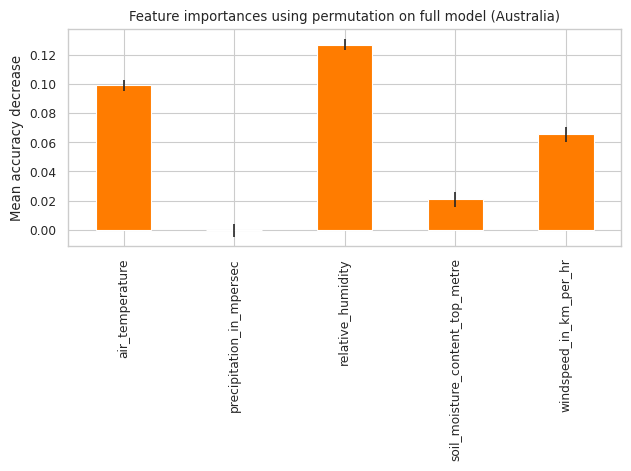

<Figure size 640x480 with 0 Axes>

In [35]:
fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=result.importances_std, ax=ax)
ax.set_title("Feature importances using permutation on full model (Australia)")
ax.set_ylabel("Mean accuracy decrease")
fig.tight_layout()
plt.show()
plt.savefig('/data/users/andrew.hartley/Projects/FFDI_Paper/plots/meteorological-drivers-Australia_variable_importance.png')

In [36]:
output = []
countries = ['Australia', 'Brazil', 'United States of America']  # 'South Africa', 

# for ffdi_class in ['12 <= FFDI < 24', 'FFDI >= 24']:
for country in countries:
    # Subset the big dataframe
    mysample = df_final[df_final.names.isin([country])].sample(frac=0.1, replace=False)
    # mysample = df_final[(df_final.names.isin([country])) & (df_final.ffdi_class.isin([ffdi_class]))].sample(frac=0.1, replace=False)
    mysample['ffdi_class_int'] = 0
    mysample['ffdi_class_int'].loc[mysample['ffdi_class'] == 'FFDI >= 24'] = 1

    # Extract training and test data
    feature_names = ['air_temperature', 'precipitation_in_mpersec', 'relative_humidity', 'soil_moisture_content_top_metre', 'windspeed_in_km_per_hr']
    X_features = mysample[feature_names]
    y_classes = mysample[['FFDI']].astype(int)
    X_train, X_test, y_train, y_test = train_test_split(X_features, y_classes, stratify=mysample['ffdi_class_int'], random_state=42)
    # X_train, X_test, y_train, y_test = train_test_split(X_features, y_classes, random_state=42)

    # Run the RF classifier
    forest = RandomForestClassifier(random_state=0)
    forest.fit(X_train, y_train)

    # Get the variable importance using the test data
    result = permutation_importance(forest, X_test, y_test, n_repeats=10, random_state=42, n_jobs=2)
    forest_importances = pd.Series(result.importances_mean, index=feature_names)

    # Add into a DataFrame
    if isinstance(output, list):
        output = pd.DataFrame({'importances': forest_importances, 'importances_std': result.importances_std, 'country': country})
    else:
        newoutput = pd.DataFrame({'importances': forest_importances, 'importances_std': result.importances_std, 'country': country})
        output = pd.concat([output, newoutput])
    
# Now convert the index into a column
output = output.reset_index(inplace=False).rename(columns={'index': 'Variable'})
# Make columns categorical to help with plotting
output['Variable'] = pd.Categorical(output['Variable'], output['Variable'].unique())
output['country'] = pd.Categorical(output['country'], output['country'].unique())
# Make variable names nicer for plotting
lookup = {'air_temperature': 'T', 'precipitation_in_mpersec': 'Pr', 'relative_humidity': 'RH', 'soil_moisture_content_top_metre': 'SM', 'windspeed_in_km_per_hr': 'W'}
output['Variable_nice'] = 'T'
for k, v in lookup.items():
    output['Variable_nice'].loc[output['Variable'] == k] = v

output

,Variable,importances,importances_std,country,Variable_nice
0,air_temperature,0.086720,0.004573,Australia,T
1,precipitation_in_mpersec,0.000604,0.003132,Australia,Pr
2,relative_humidity,0.115292,0.003830,Australia,RH
3,soil_moisture_content_top_metre,0.018109,0.004527,Australia,SM
4,windspeed_in_km_per_hr,0.059205,0.004056,Australia,W
5,air_temperature,0.158788,0.006833,Brazil,T
6,precipitation_in_mpersec,0.007879,0.006223,Brazil,Pr
7,relative_humidity,0.222020,0.011761,Brazil,RH
8,soil_moisture_content_top_metre,0.060808,0.013980,Brazil,SM
9,windspeed_in_km_per_hr,0.143232,0.010437,Brazil,W


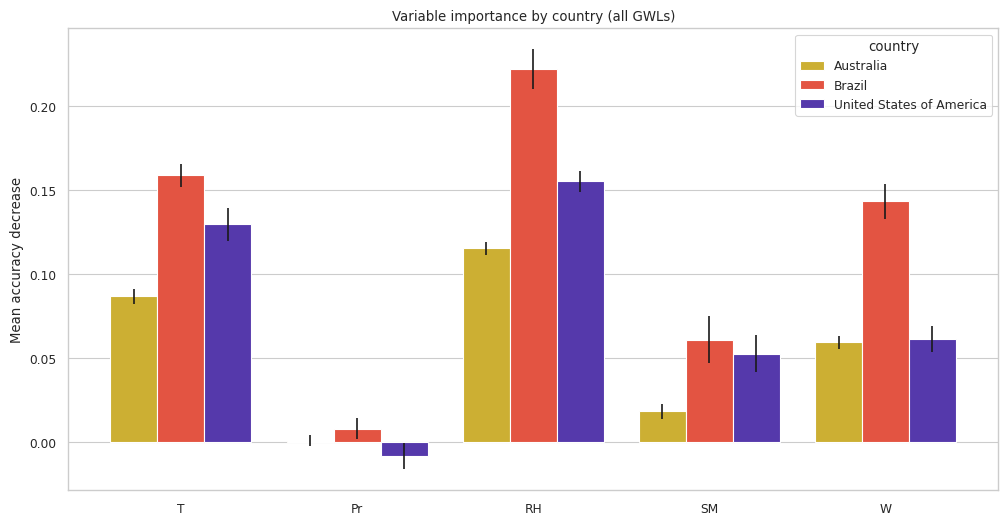

In [37]:
n = len(countries)

fig = plt.figure(figsize=(12, 6))
ax = sns.barplot(data=output, x='Variable_nice', y='importances', hue='country', palette='CMRmap_r')
# Do something with error bars
# Based on https://stackoverflow.com/questions/72352491/how-to-plot-errorbars-on-seaborn-barplot 
x_coords = [p.get_x() + 0.5 * p.get_width() for p in ax.patches]
y_coords = [p.get_height() for p in ax.patches]
ax.errorbar(x=x_coords[:-n], y=y_coords[:-n], yerr=output["importances_std"], fmt="none", c="k")

ax.set_title("Variable importance by country (all GWLs)")
ax.set_ylabel("Mean accuracy decrease")
ax.set_xlabel("")
plt.savefig(f'/data/users/andrew.hartley/Projects/FFDI_Paper/plots/meteorological-drivers_variable_importance_{clen}countries_allGWLs-Stratification.png')

In [38]:
output = []
countries = ['Australia', 'Brazil', 'United States of America']  # 'South Africa', 

# for ffdi_class in ['12 <= FFDI < 24', 'FFDI >= 24']:
for gwl in ['Baseline', "GWL4"]:
    for country in countries:
        # Subset the big dataframe
        # mysample = df_final[df_final.names.isin([country])].sample(frac=0.1, replace=False)
        mysample = df_final[(df_final.names.isin([country])) & (df_final.gwl.isin([gwl]))].sample(frac=0.1, replace=False)
        mysample['ffdi_class_int'] = 0
        mysample['ffdi_class_int'].loc[mysample['ffdi_class'] == 'FFDI >= 24'] = 1
    
        # Extract training and test data
        feature_names = ['air_temperature', 'precipitation_in_mpersec', 'relative_humidity', 'soil_moisture_content_top_metre', 'windspeed_in_km_per_hr']
        X_features = mysample[feature_names]
        y_classes = mysample[['FFDI']].astype(int)
        X_train, X_test, y_train, y_test = train_test_split(X_features, y_classes, stratify=mysample['ffdi_class_int'], random_state=42)
    
        # Run the RF classifier
        forest = RandomForestClassifier(random_state=0)
        forest.fit(X_train, y_train)
    
        # Get the variable importance using the test data
        result = permutation_importance(forest, X_test, y_test, n_repeats=10, random_state=42, n_jobs=2)
        forest_importances = pd.Series(result.importances_mean, index=feature_names)
    
        # Add into a DataFrame
        if isinstance(output, list):
            output = pd.DataFrame({'importances': forest_importances, 'importances_std': result.importances_std, 'country': country, 'gwl': gwl})
        else:
            newoutput = pd.DataFrame({'importances': forest_importances, 'importances_std': result.importances_std, 'country': country, 'gwl': gwl})
            output = pd.concat([output, newoutput])
    
# Now convert the index into a column
output = output.reset_index(inplace=False).rename(columns={'index': 'Variable'})
# Make columns categorical to help with plotting
output['Variable'] = pd.Categorical(output['Variable'], output['Variable'].unique())
output['country'] = pd.Categorical(output['country'], output['country'].unique())
output['gwl'] = pd.Categorical(output['gwl'], output['gwl'].unique())
# Make variable names nicer for plotting
lookup = {'air_temperature': 'T', 'precipitation_in_mpersec': 'Pr', 'relative_humidity': 'RH', 'soil_moisture_content_top_metre': 'SM', 'windspeed_in_km_per_hr': 'W'}
output['Variable_nice'] = 'T'
for k, v in lookup.items():
    output['Variable_nice'].loc[output['Variable'] == k] = v

output

,Variable,importances,importances_std,country,gwl,Variable_nice
0,air_temperature,0.055056,0.007311,Australia,Baseline,T
1,precipitation_in_mpersec,-0.001124,0.004678,Australia,Baseline,Pr
2,relative_humidity,0.080524,0.009401,Australia,Baseline,RH
3,soil_moisture_content_top_metre,0.000187,0.010238,Australia,Baseline,SM
4,windspeed_in_km_per_hr,0.031648,0.005584,Australia,Baseline,W
5,air_temperature,0.115217,0.021300,Brazil,Baseline,T
6,precipitation_in_mpersec,-0.010870,0.020042,Brazil,Baseline,Pr
7,relative_humidity,0.181522,0.021217,Brazil,Baseline,RH
8,soil_moisture_content_top_metre,0.045652,0.033254,Brazil,Baseline,SM
9,windspeed_in_km_per_hr,0.052174,0.021077,Brazil,Baseline,W


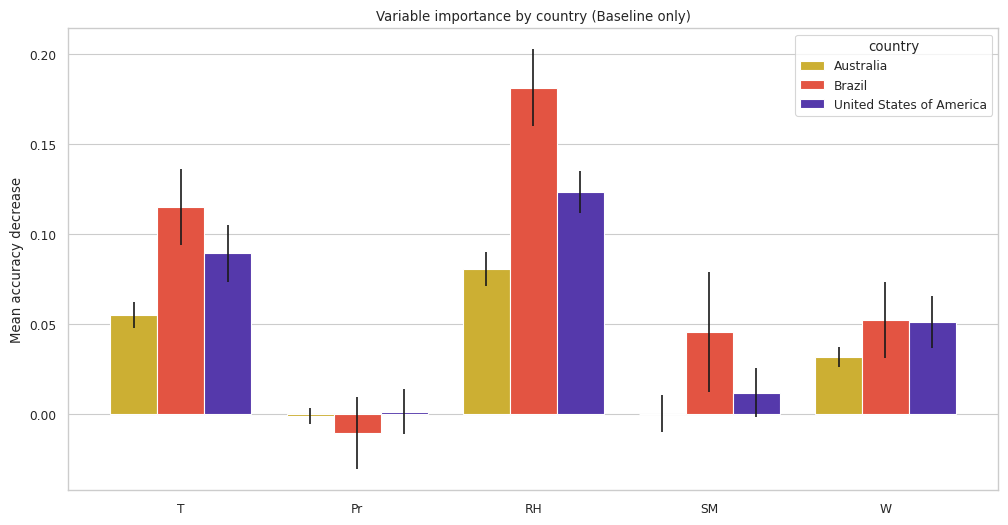

In [39]:
n = len(countries)

fig = plt.figure(figsize=(12, 6))
ax = sns.barplot(data=output.loc[output.gwl == 'Baseline'], x='Variable_nice', y='importances', hue='country', palette='CMRmap_r')
# Do something with error bars
# Based on https://stackoverflow.com/questions/72352491/how-to-plot-errorbars-on-seaborn-barplot 
x_coords = [p.get_x() + 0.5 * p.get_width() for p in ax.patches]
y_coords = [p.get_height() for p in ax.patches]
ax.errorbar(x=x_coords[:-n], y=y_coords[:-n], yerr=output.loc[output.gwl == 'Baseline']["importances_std"], fmt="none", c="k")

ax.set_title("Variable importance by country (Baseline only)")
ax.set_ylabel("Mean accuracy decrease")
ax.set_xlabel("")
plt.savefig(f'/data/users/andrew.hartley/Projects/FFDI_Paper/plots/meteorological-drivers_variable_importance_{clen}countries_Baseline.png')

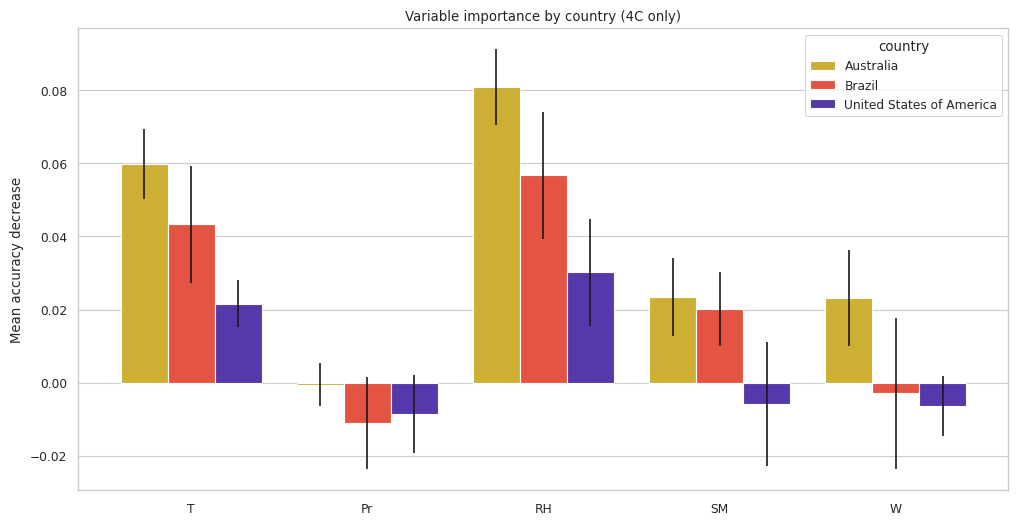

In [40]:
n = len(countries)

fig = plt.figure(figsize=(12, 6))
ax = sns.barplot(data=output.loc[output.gwl == 'GWL4'], x='Variable_nice', y='importances', hue='country', palette='CMRmap_r')
# Do something with error bars
# Based on https://stackoverflow.com/questions/72352491/how-to-plot-errorbars-on-seaborn-barplot 
x_coords = [p.get_x() + 0.5 * p.get_width() for p in ax.patches]
y_coords = [p.get_height() for p in ax.patches]
ax.errorbar(x=x_coords[:-n], y=y_coords[:-n], yerr=output.loc[output.gwl == 'GWL4']["importances_std"], fmt="none", c="k")

ax.set_title("Variable importance by country (4C only)")
ax.set_ylabel("Mean accuracy decrease")
ax.set_xlabel("")
plt.savefig(f'/data/users/andrew.hartley/Projects/FFDI_Paper/plots/meteorological-drivers_variable_importance_{clen}countries_GWL4.png')

In [41]:
output = []
countries = ['Australia', 'Brazil', 'United States of America']  # 'South Africa', 

for ffdi_class in ['12 <= FFDI < 24', 'FFDI >= 24']:
# for gwl in ['Baseline', "GWL4"]:
    for country in countries:
        # Subset the big dataframe
        # mysample = df_final[df_final.names.isin([country])].sample(frac=0.1, replace=False)
        mysample = df_final[(df_final.names.isin([country])) & (df_final.ffdi_class.isin([ffdi_class]))].sample(frac=0.1, replace=False)
        # mysample['ffdi_class_int'] = 0
        # mysample['ffdi_class_int'].loc[mysample['ffdi_class'] == 'FFDI >= 24'] = 1
    
        # Extract training and test data
        feature_names = ['air_temperature', 'precipitation_in_mpersec', 'relative_humidity', 'soil_moisture_content_top_metre', 'windspeed_in_km_per_hr']
        X_features = mysample[feature_names]
        y_classes = mysample[['FFDI']].astype(int)
        X_train, X_test, y_train, y_test = train_test_split(X_features, y_classes, random_state=42)
    
        # Run the RF classifier
        forest = RandomForestClassifier(random_state=0)
        forest.fit(X_train, y_train)
    
        # Get the variable importance using the test data
        result = permutation_importance(forest, X_test, y_test, n_repeats=10, random_state=42, n_jobs=2)
        forest_importances = pd.Series(result.importances_mean, index=feature_names)
    
        # Add into a DataFrame
        if isinstance(output, list):
            output = pd.DataFrame({'importances': forest_importances, 'importances_std': result.importances_std, 'country': country, 'ffdi_class': ffdi_class})
        else:
            newoutput = pd.DataFrame({'importances': forest_importances, 'importances_std': result.importances_std, 'country': country, 'ffdi_class': ffdi_class})
            output = pd.concat([output, newoutput])
    
# Now convert the index into a column
output = output.reset_index(inplace=False).rename(columns={'index': 'Variable'})
# Make columns categorical to help with plotting
output['Variable'] = pd.Categorical(output['Variable'], output['Variable'].unique())
output['country'] = pd.Categorical(output['country'], output['country'].unique())
output['ffdi_class'] = pd.Categorical(output['ffdi_class'], output['ffdi_class'].unique())
# Make variable names nicer for plotting
lookup = {'air_temperature': 'T', 'precipitation_in_mpersec': 'Pr', 'relative_humidity': 'RH', 'soil_moisture_content_top_metre': 'SM', 'windspeed_in_km_per_hr': 'W'}
output['Variable_nice'] = 'T'
for k, v in lookup.items():
    output['Variable_nice'].loc[output['Variable'] == k] = v

output

,Variable,importances,importances_std,country,ffdi_class,Variable_nice
0,air_temperature,0.103448,0.009008,Australia,12 <= FFDI < 24,T
1,precipitation_in_mpersec,0.008046,0.004719,Australia,12 <= FFDI < 24,Pr
2,relative_humidity,0.134306,0.005723,Australia,12 <= FFDI < 24,RH
3,soil_moisture_content_top_metre,0.026879,0.008905,Australia,12 <= FFDI < 24,SM
4,windspeed_in_km_per_hr,0.072591,0.008336,Australia,12 <= FFDI < 24,W
5,air_temperature,0.162411,0.010469,Brazil,12 <= FFDI < 24,T
6,precipitation_in_mpersec,-0.006619,0.011811,Brazil,12 <= FFDI < 24,Pr
7,relative_humidity,0.235697,0.012286,Brazil,12 <= FFDI < 24,RH
8,soil_moisture_content_top_metre,0.025532,0.007310,Brazil,12 <= FFDI < 24,SM
9,windspeed_in_km_per_hr,0.154846,0.010154,Brazil,12 <= FFDI < 24,W


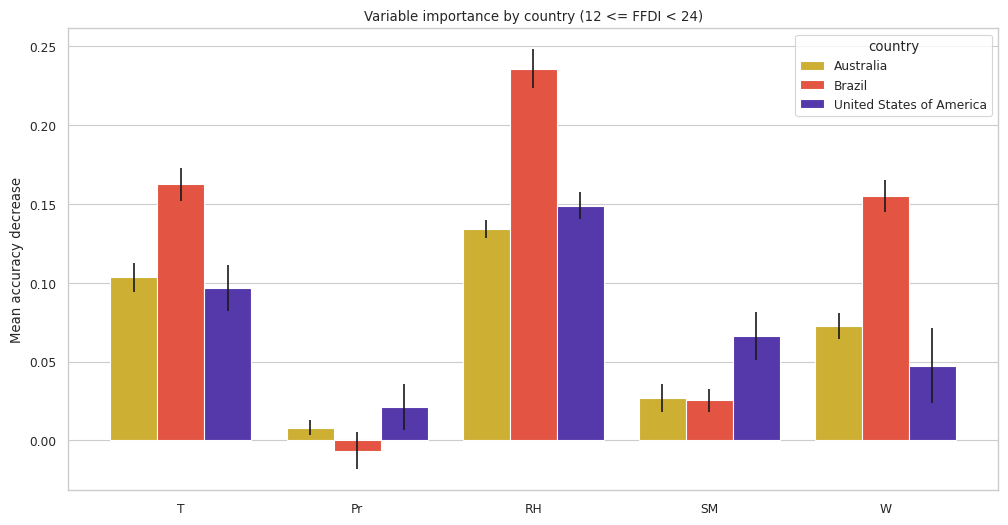

In [42]:
n = len(countries)
# '12 <= FFDI < 24', 'FFDI >= 24'
fig = plt.figure(figsize=(12, 6))
ax = sns.barplot(data=output.loc[output.ffdi_class == '12 <= FFDI < 24'], x='Variable_nice', y='importances', hue='country', palette='CMRmap_r')
# Do something with error bars
# Based on https://stackoverflow.com/questions/72352491/how-to-plot-errorbars-on-seaborn-barplot 
x_coords = [p.get_x() + 0.5 * p.get_width() for p in ax.patches]
y_coords = [p.get_height() for p in ax.patches]
ax.errorbar(x=x_coords[:-n], y=y_coords[:-n], yerr=output.loc[output.ffdi_class == '12 <= FFDI < 24']["importances_std"], fmt="none", c="k")

ax.set_title("Variable importance by country (12 <= FFDI < 24)")
ax.set_ylabel("Mean accuracy decrease")
ax.set_xlabel("")
plt.savefig(f'/data/users/andrew.hartley/Projects/FFDI_Paper/plots/meteorological-drivers_variable_importance_{clen}countries_12FFDI24.png')

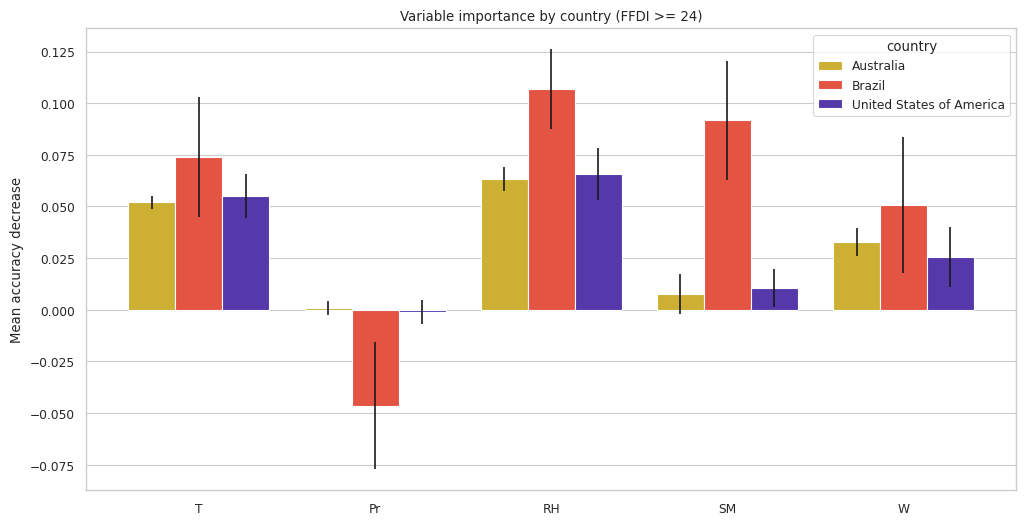

In [43]:
n = len(countries)
# '12 <= FFDI < 24', 'FFDI >= 24'
fig = plt.figure(figsize=(12, 6))
ax = sns.barplot(data=output.loc[output.ffdi_class == 'FFDI >= 24'], x='Variable_nice', y='importances', hue='country', palette='CMRmap_r')
# Do something with error bars
# Based on https://stackoverflow.com/questions/72352491/how-to-plot-errorbars-on-seaborn-barplot 
x_coords = [p.get_x() + 0.5 * p.get_width() for p in ax.patches]
y_coords = [p.get_height() for p in ax.patches]
ax.errorbar(x=x_coords[:-n], y=y_coords[:-n], yerr=output.loc[output.ffdi_class == 'FFDI >= 24']["importances_std"], fmt="none", c="k")

ax.set_title("Variable importance by country (FFDI >= 24)")
ax.set_ylabel("Mean accuracy decrease")
ax.set_xlabel("")
plt.savefig(f'/data/users/andrew.hartley/Projects/FFDI_Paper/plots/meteorological-drivers_variable_importance_{clen}countries_FFDIgt24.png')

# Sampling for the paper

In [ ]:
# TODO: Sample [xcoord, ycoord, ens member, country] from the baseline, and then use the same coordinates for the 4C. Then save these coordinates for reproducibility
#           Within that set, then threshold FFDI >= 24, then sample from the set that comes back for both baseline and 4C
